# Análisis de conceptos candidatos a puentes entre emociones

Análisis numérico de los conceptos obtenidos en los caminos de ConceptNet. 
El propósito es no saturar la ipynb analysis para trabajar en limpio. 
Para le 06/11/26 sólo se trabajarán las palabras obtenidas entre los conjuntos de altamente prototípcas de felicidad y tristeza ya filtrados con EmoPro y ConceptNet para eliminar los conceptos emocionales.
---
### To do:
- Retoma el diccionario con los conteos de los conceptos.
- Revisar si es posible hacer otro filtrado 
- Comenzar a seleccionar los conceptos candidatos 
- Graficar la distribución del conjunto

In [4]:
import pandas as pd
import pickle
import csv
import seaborn as sns

from matplotlib import pyplot as plt


In [5]:
help(csv.reader)

Help on built-in function reader in module _csv:

reader(...)
    csv_reader = reader(iterable [, dialect='excel']
                            [optional keyword args])
        for row in csv_reader:
            process(row)
    
    The "iterable" argument can be any object that returns a line
    of input for each iteration, such as a file object or a list.  The
    optional "dialect" parameter is discussed below.  The function
    also accepts optional keyword arguments which override settings
    provided by the dialect.
    
    The returned object is an iterator.  Each iteration returns a row
    of the CSV file (which can span multiple input lines).



In [6]:
candidatos_esp = []
candidatos_ing = []
with open('candidatos/candidatos_esp.csv', 'r') as f:
   reader = csv.reader(f)
   for row in reader:
       candidatos_esp.append(row[0])
with open('candidatos/candidatos_ing.csv', 'r') as f:
   reader = csv.reader(f)
   for row in reader:
       candidatos_ing.append(row[0])

with open('data/candidatos_puentes.pickle', 'rb') as f:
    conteos = pickle.load(f)

In [7]:
'sad' in candidatos_ing

True

In [8]:
conteos_esp = {}
conteos_ing = {}


for p in candidatos_esp:
    conteos_esp[p] = conteos[p]


for w in candidatos_ing:
    conteos_ing[w]=conteos[w]



In [9]:
def graficador(datos:list) -> None:
    ordenadas = sorted(datos.items(), key = lambda x: x[1], reverse=True)
    frecuencias = [frec for p,frec in ordenadas]
    rank = range(1, len(frecuencias) + 1)
    plt.figure(figsize=(9,5))
    plt.plot(rank, frecuencias, color='r')

    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('Rangos de palabras (Log)')
    plt.ylabel('Frecuencias (Log)')
    plt.title('Distribución de Frecuencias (Ley Zipf)')
    plt.grid(True, which='both', linestyle = '--', alpha = 0.5)
    plt.show()

    plt.figure(figsize=(9,5))
    sns.histplot(frecuencias, bins= 50, kde=True, color='teal')
    plt.xlabel('Frecuencia de la palabra')
    plt.ylabel('Cantidad de palabras')
    plt.title('Distribución de Frecuencias en el Corpus')
    plt.show()
    top_n = 50
    top_w = ordenadas[:top_n]

    p, f = zip(*top_w)

    plt.figure(figsize=(13, 10))
    sns.barplot(x=list(f), y=list(p), palette='viridis')
    plt.xlabel('Frecuencia')
    plt.ylabel('Palabra')
    plt.title(f'Top {top_n} palabras más frecuentes')
    plt.show()


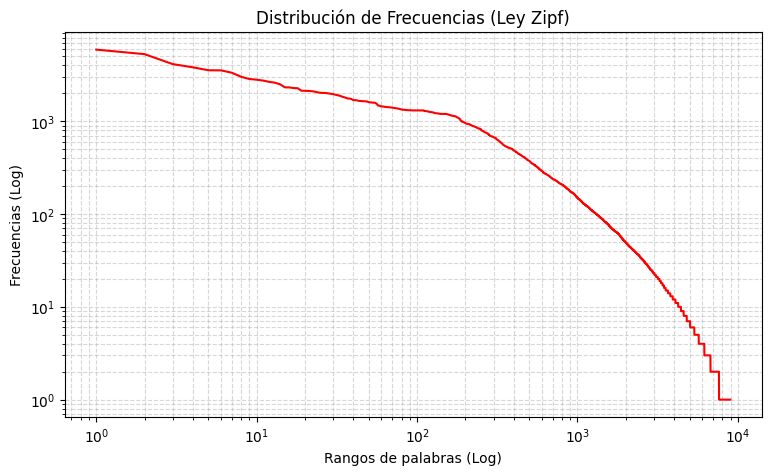

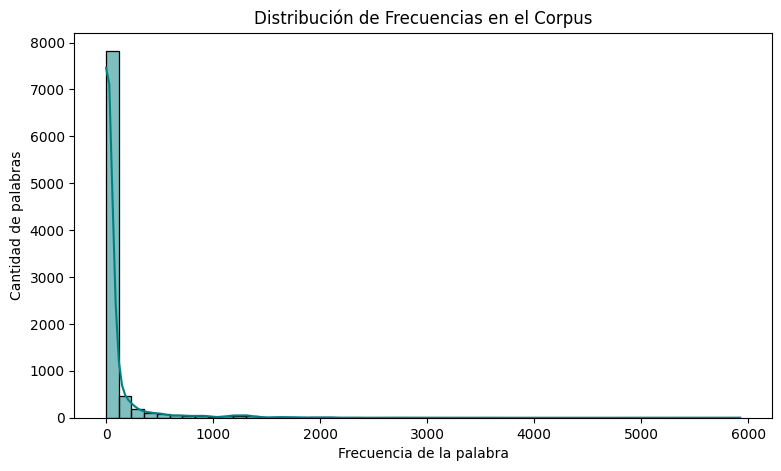

/tmp/ipykernel_19706/3651892859.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(f), y=list(p), palette='viridis')


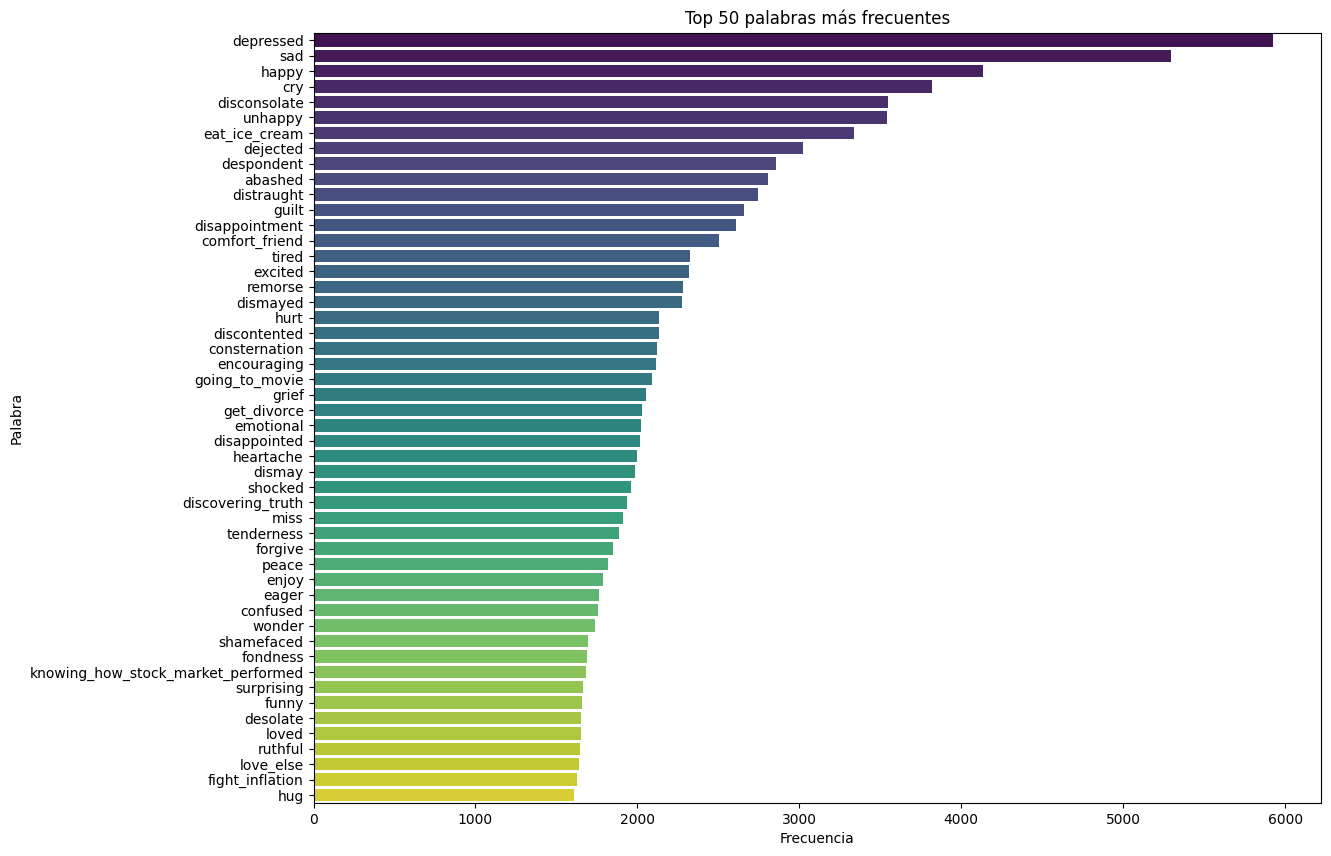

In [10]:
graficador(conteos_ing)

In [14]:
todos = []
with open('candidatos/candidatos_finales.csv', 'r') as f:
    reader = csv.reader(f)
    for row in reader:
       todos.append(row)

In [ ]:
todos
for i in todos:
    


[['a', 'd', 'm', 'i', 'r', 'a', 't', 'i', 'o', 'n'],
 ['w',
  'a',
  't',
  'c',
  'h',
  'i',
  'n',
  'g',
  '_',
  'm',
  'u',
  's',
  'i',
  'c',
  'i',
  'a',
  'n',
  '_',
  'p',
  'e',
  'r',
  'f',
  'o',
  'r',
  'm'],
 ['d', 'e', 'p', 'r', 'e', 's', 's', 'e', 'd'],
 ['w', 'o', 'n', 'd', 'e', 'r'],
 ['d', 'i', 's', 'c', 'o', 'v', 'e', 'r', '_', 't', 'r', 'u', 't', 'h'],
 ['c', 'o', 'm', 'm', 'i', 't', '_', 's', 'u', 'i', 'c', 'i', 'd', 'e'],
 ['u', 'n', 'h', 'a', 'p', 'p', 'y'],
 ['g',
  'o',
  '_',
  't',
  'o',
  '_',
  'p',
  'e',
  'r',
  'f',
  'o',
  'r',
  'm',
  'a',
  'n',
  'c',
  'e'],
 ['h', 'a', 'v', 'e', '_', 'f', 'u', 'n'],
 ['e', 'a', 't', '_', 'i', 'c', 'e', '_', 'c', 'r', 'e', 'a', 'm'],
 ['c', 'r', 'y'],
 ['d', 'e', 's', 'p', 'o', 'n', 'd', 'e', 'n', 't'],
 ['a', 's', 't', 'o', 'n', 'i', 's', 'h', 'm', 'e', 'n', 't'],
 ['s', 'e', 'e', 'i', 'n', 'g', '_', 'n', 'e', 'w'],
 ['g', 'o', 'i', 'n', 'g', '_', 't', 'o', '_', 'm', 'o', 'v', 'i', 'e'],
 ['f', 'o', 'r'